vol-managed spy + low-beta sector pair. data via yfinance, runs top to bottom in colab (~1–2 min).

- sleeve 1: hold `TARGET_VOL / vol_21d` in spy, cap 2x, reset at month-end. rest in t-bills, borrow at t-bill + 50bp above 1x.
- sleeve 2: each year-end take the 2 lowest-beta sector etfs vs spy (past 1y). `z = (log(a/b) - mean_60) / std_60`. |z| > 2 → long cheap, short rich, 1x per leg. exit at |z| < 0.5.

In [1]:
%pip install -q yfinance statsmodels
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, yfinance as yf
pd.set_option('display.width', 200)
print('yfinance', yf.__version__, '| pandas', pd.__version__)

/tmp/claude-0/-home-user-FinancialModellingGroupN/0d685fe3-a9d9-53c6-8ec7-41b7553e8539/scratchpad/colabenv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


yfinance 1.8.0 | pandas 2.2.2


### params

In [2]:
START, END = '2006-01-01', '2025-12-31'   # evaluation window: first and last return day (inclusive)
DATA_START = '1999-01-01'                 # sector ETFs start Dec-1998; earlier years serve as warm-up / formation data
IS_END = '2015-12-31'                     # split for the in-sample / out-of-sample check

# Sleeve 1: volatility-managed SPY
TARGET_VOL = 0.15     # annualised volatility target
VOL_DAYS   = 21       # look-back for realised volatility (~1 month)
MAX_LEV    = 2.0      # cap on SPY exposure

# Sleeve 2: pair overlay
SECTORS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']   # the 9 original Select Sector SPDRs
BETA_YEARS = 1        # look-back (calendar years) for the beta estimate used to pick the pair
Z_WIN, Z_IN, Z_OUT = 60, 2.0, 0.5
PAIR_SIZE = 1.0       # notional per leg as a fraction of equity

# Implementation costs
COST       = 0.0010   # 10 bp of notional traded (spread + commission + slippage)
FIN_SPREAD = 0.0050   # borrowing cost above the T-bill rate, p.a.
SHORT_FEE  = 0.0025   # stock-borrow fee on short notional, p.a.

ASSETS  = ['SPY'] + SECTORS
TICKERS = ASSETS + ['^SP500TR', '^IRX']

### data
- yfinance, `auto_adjust=True` → split + dividend adjusted, i.e. total returns
- universe: spy + 9 original sector spdrs, all live since dec-1998, fixed upfront → no survivorship
- benchmark: `^SP500TR`
- rf: `^IRX / 100 / 252`, lagged 1 day
- signals daily, stats on monthly returns

In [3]:
raw = yf.download(TICKERS, start=DATA_START, end=pd.Timestamp(END) + pd.Timedelta(days=1),
                  auto_adjust=True, progress=False)['Close'][TICKERS]

# The four checks from Lecture 3: shape, date range, missing values, plot
print('shape:', raw.shape)
print('date range:', raw.index.min().date(), '->', raw.index.max().date())
print('missing values per column:\n', raw.isna().sum().to_string())

shape: (6791, 12)
date range: 1999-01-04 -> 2025-12-31
missing values per column:
 Ticker
SPY         0
XLB         0
XLE         0
XLF         0
XLI         0
XLK         0
XLP         0
XLU         0
XLV         0
XLY         0
^SP500TR    0
^IRX        8


dropna removed 0 of 6791 rows; sample now 1999-01-04 -> 2025-12-31


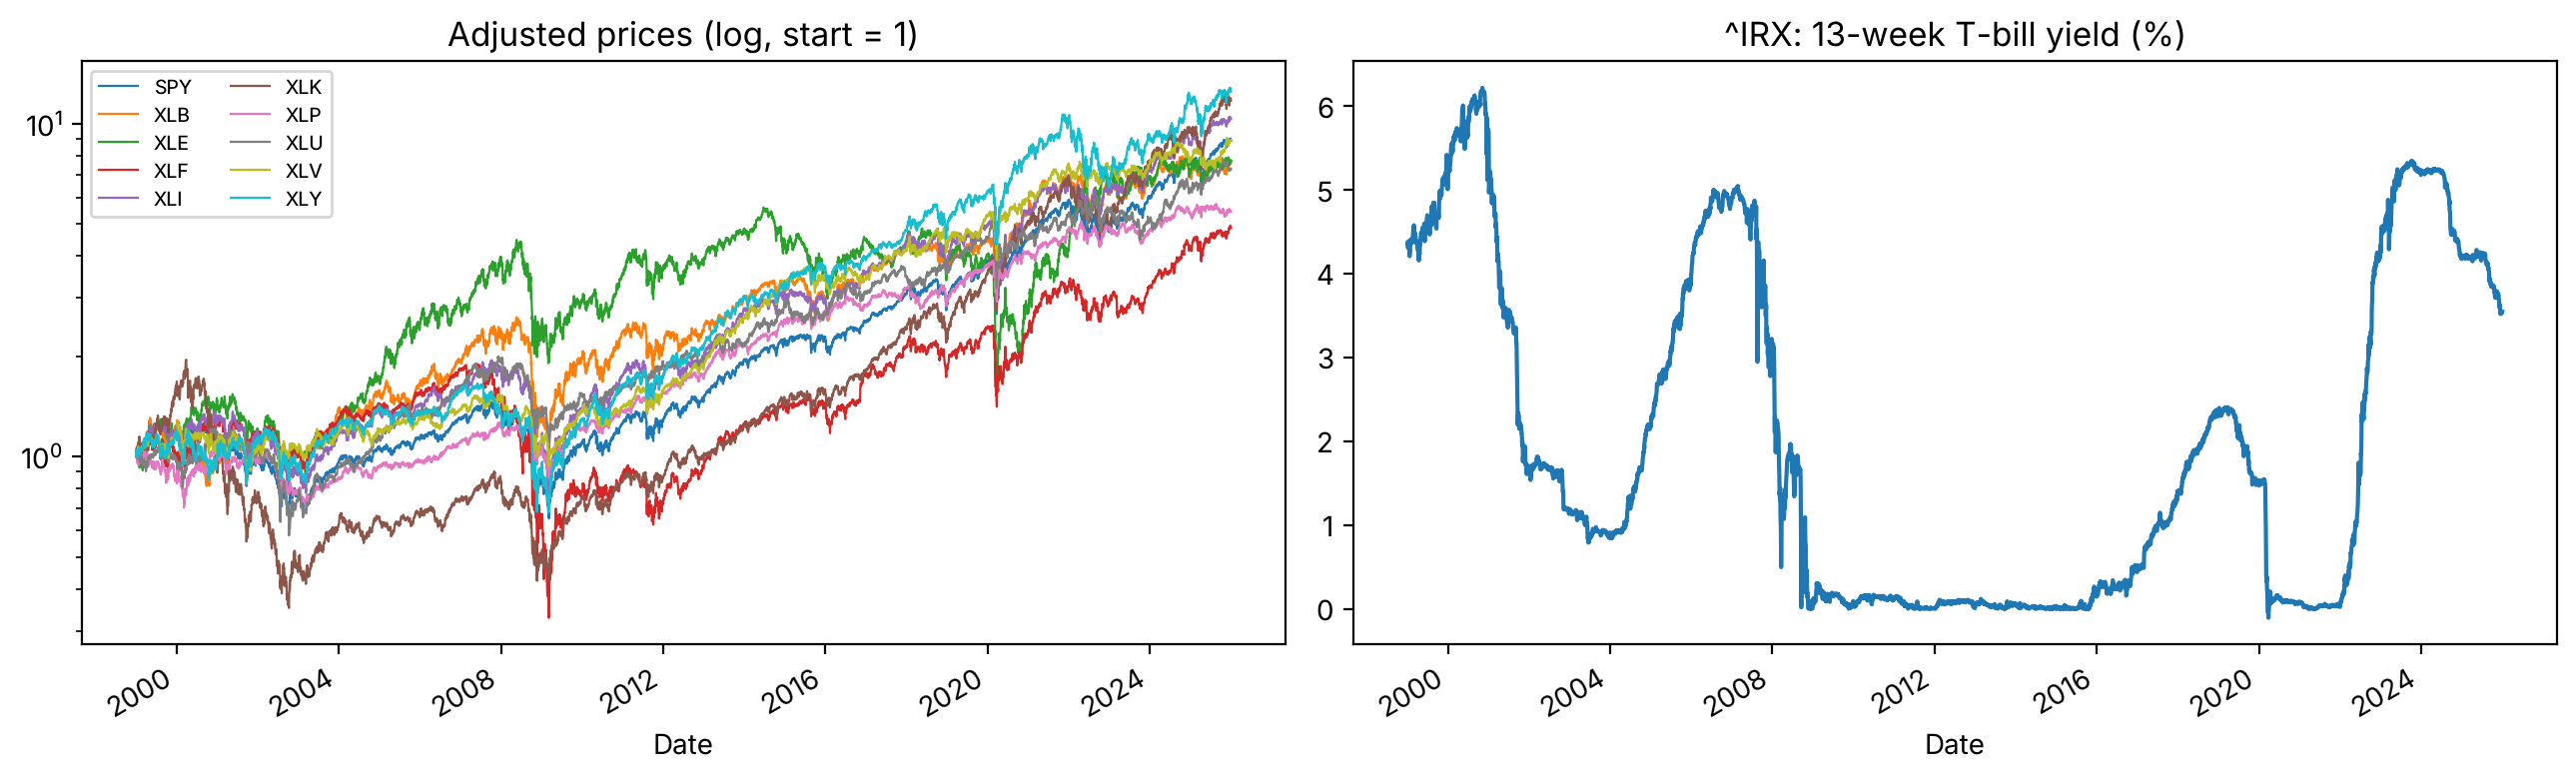

In [4]:
assert raw[ASSETS + ['^SP500TR']].notna().all().all(), 'download incomplete (rate limit?): re-run this cell'
px = raw.copy()
px['^IRX'] = px['^IRX'].ffill()           # T-bill quote occasionally missing on a trading day: carry last yield
n0 = len(px)
px = px.dropna()
print(f'dropna removed {n0 - len(px)} of {n0} rows; sample now {px.index.min().date()} -> {px.index.max().date()}')
assert px.index.min() < pd.Timestamp(START) and px.index.max() == pd.Timestamp(END), 'sample does not cover START..END'

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(px[ASSETS] / px[ASSETS].iloc[0]).plot(ax=ax[0], logy=True, lw=.8, title='Adjusted prices (log, start = 1)')
ax[0].legend(ncol=2, fontsize=7)
px['^IRX'].plot(ax=ax[1], title='^IRX: 13-week T-bill yield (%)')
plt.tight_layout(); plt.show()

In [5]:
ret = px[ASSETS + ['^SP500TR']].pct_change()
rf_d = (px['^IRX'] / 100 / 252).shift(1)     # yield known at t-1 is earned on day t

# Sanity check: SPY (adjusted) vs the S&P 500 total-return index should differ only by SPY's ~0.09% fee
yr = (1 + ret.loc[START:END, ['SPY', '^SP500TR']]).groupby(lambda d: d.year).prod() - 1
print('mean annual return SPY vs ^SP500TR:', yr.mean().round(4).to_dict(),
      '| correlation of daily returns:', round(ret.loc[START:END, 'SPY'].corr(ret.loc[START:END, '^SP500TR']), 4))

mean annual return SPY vs ^SP500TR: {'SPY': 0.1243, '^SP500TR': 0.1252} | correlation of daily returns: 0.9938


### signals
only closes ≤ t. trade at close t, earn from t+1. pair for year y picked at the last close of y−1. a new pair starts flat, so opening it needs |z| > 2.

In [6]:
from itertools import groupby

def month_end_flag(idx):
    return ~idx.to_period('M').duplicated(keep='last')                 # last trading day of each month

def spy_exposure(px):
    vol = px['SPY'].pct_change().rolling(VOL_DAYS).std() * np.sqrt(252)   # trailing window ending at t
    return (TARGET_VOL / vol).clip(upper=MAX_LEV)

def sector_betas(px, lo, hi):
    r = px[ASSETS].pct_change().loc[lo:hi]
    return r.cov()['SPY'][SECTORS] / r['SPY'].var()                    # beta = cov / var (lecture 3)

def lowbeta_pick(px, year, years=BETA_YEARS):
    # the two lowest-beta sectors over the `years` calendar years before `year`
    return tuple(sorted(sector_betas(px, str(year - years), str(year - 1)).nsmallest(2).index))

def zscore(px, a, b, win=Z_WIN):
    s = np.log(px[a] / px[b])
    return (s - s.rolling(win).mean()) / s.rolling(win).std()           # trailing window ending at t

def positions(z, z_in=Z_IN, z_out=Z_OUT):
    pos, p = [], 0
    for zt in z:
        if np.isnan(zt):                 p = 0
        elif p == 0 and zt >  z_in:      p = -1   # a rich vs b: short a, long b
        elif p == 0 and zt < -z_in:      p = +1   # a cheap vs b: long a, short b
        elif p != 0 and abs(zt) < z_out: p = 0    # spread has reverted: close
        pos.append(p)
    return np.array(pos, dtype=float)

def pair_targets(px, pick=lowbeta_pick, win=Z_WIN, z_in=Z_IN, z_out=Z_OUT):
    # target sector weights per day (+1 = 100% long, -1 = 100% short) and the pair chosen for each year
    hold_year = px.index.year + (month_end_flag(px.index) & (px.index.month == 12))   # last close of december: next year's pair
    tgt = pd.DataFrame(0.0, index=px.index, columns=SECTORS)
    z_active = pd.Series(np.nan, index=px.index)
    chosen = {y: pick(px, y) for y in range(int(START[:4]), hold_year.max() + 1)}
    for (a, b), ys in groupby(chosen, key=chosen.get):                  # consecutive years with the same pair = one block
        m = np.isin(hold_year, list(ys))
        z = zscore(px, a, b, win).where(m)                              # nan outside the block, so a new pair starts flat
        pos = positions(z, z_in, z_out)
        tgt.loc[m, a] += pos[m]; tgt.loc[m, b] -= pos[m]
        z_active[m] = z[m]
    return tgt, chosen, z_active

expo = spy_exposure(px)
tgt_pair, chosen, z_active = pair_targets(px)

betas = pd.DataFrame({y: sector_betas(px, str(y - BETA_YEARS), str(y - 1)) for y in chosen}).T.round(2)
betas['pair held'] = [f'{a}/{b}' for a, b in chosen.values()]
print('Pair held each year (chosen from the prior year\'s betas):')
print(betas.loc[:int(END[:4]), 'pair held'].value_counts().to_string())
print(f"({int(END[:4]) + 1} row: pair picked at the last close of the sample, not traded in the backtest)")
betas

Pair held each year (chosen from the prior year's betas):
pair held
XLP/XLU    14
XLP/XLV     6
(2026 row: pair picked at the last close of the sample, not traded in the backtest)


Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,pair held
2006,1.21,1.37,0.98,0.99,0.94,0.71,0.97,0.73,1.08,XLP/XLV
2007,1.36,1.27,1.00,0.99,1.19,0.61,0.62,0.71,0.99,XLP/XLU
2008,1.24,1.24,1.35,0.91,0.89,0.54,0.78,0.66,0.98,XLP/XLV
2009,0.97,1.24,1.45,0.85,0.93,0.48,0.75,0.60,0.91,XLP/XLV
2010,1.13,1.18,2.15,1.14,0.88,0.50,0.54,0.54,1.09,XLP/XLV
2011,1.26,1.21,1.31,1.18,0.98,0.59,0.70,0.72,1.08,XLP/XLU
2012,1.28,1.27,1.36,1.16,0.94,0.58,0.61,0.81,1.00,XLP/XLU
2013,1.22,1.25,1.24,1.11,1.06,0.58,0.37,0.74,0.99,XLP/XLU
2014,1.12,1.08,1.21,1.07,0.88,0.82,0.73,0.94,1.05,XLP/XLU
2015,1.08,1.12,1.04,1.12,1.03,0.66,0.50,1.09,1.05,XLP/XLU


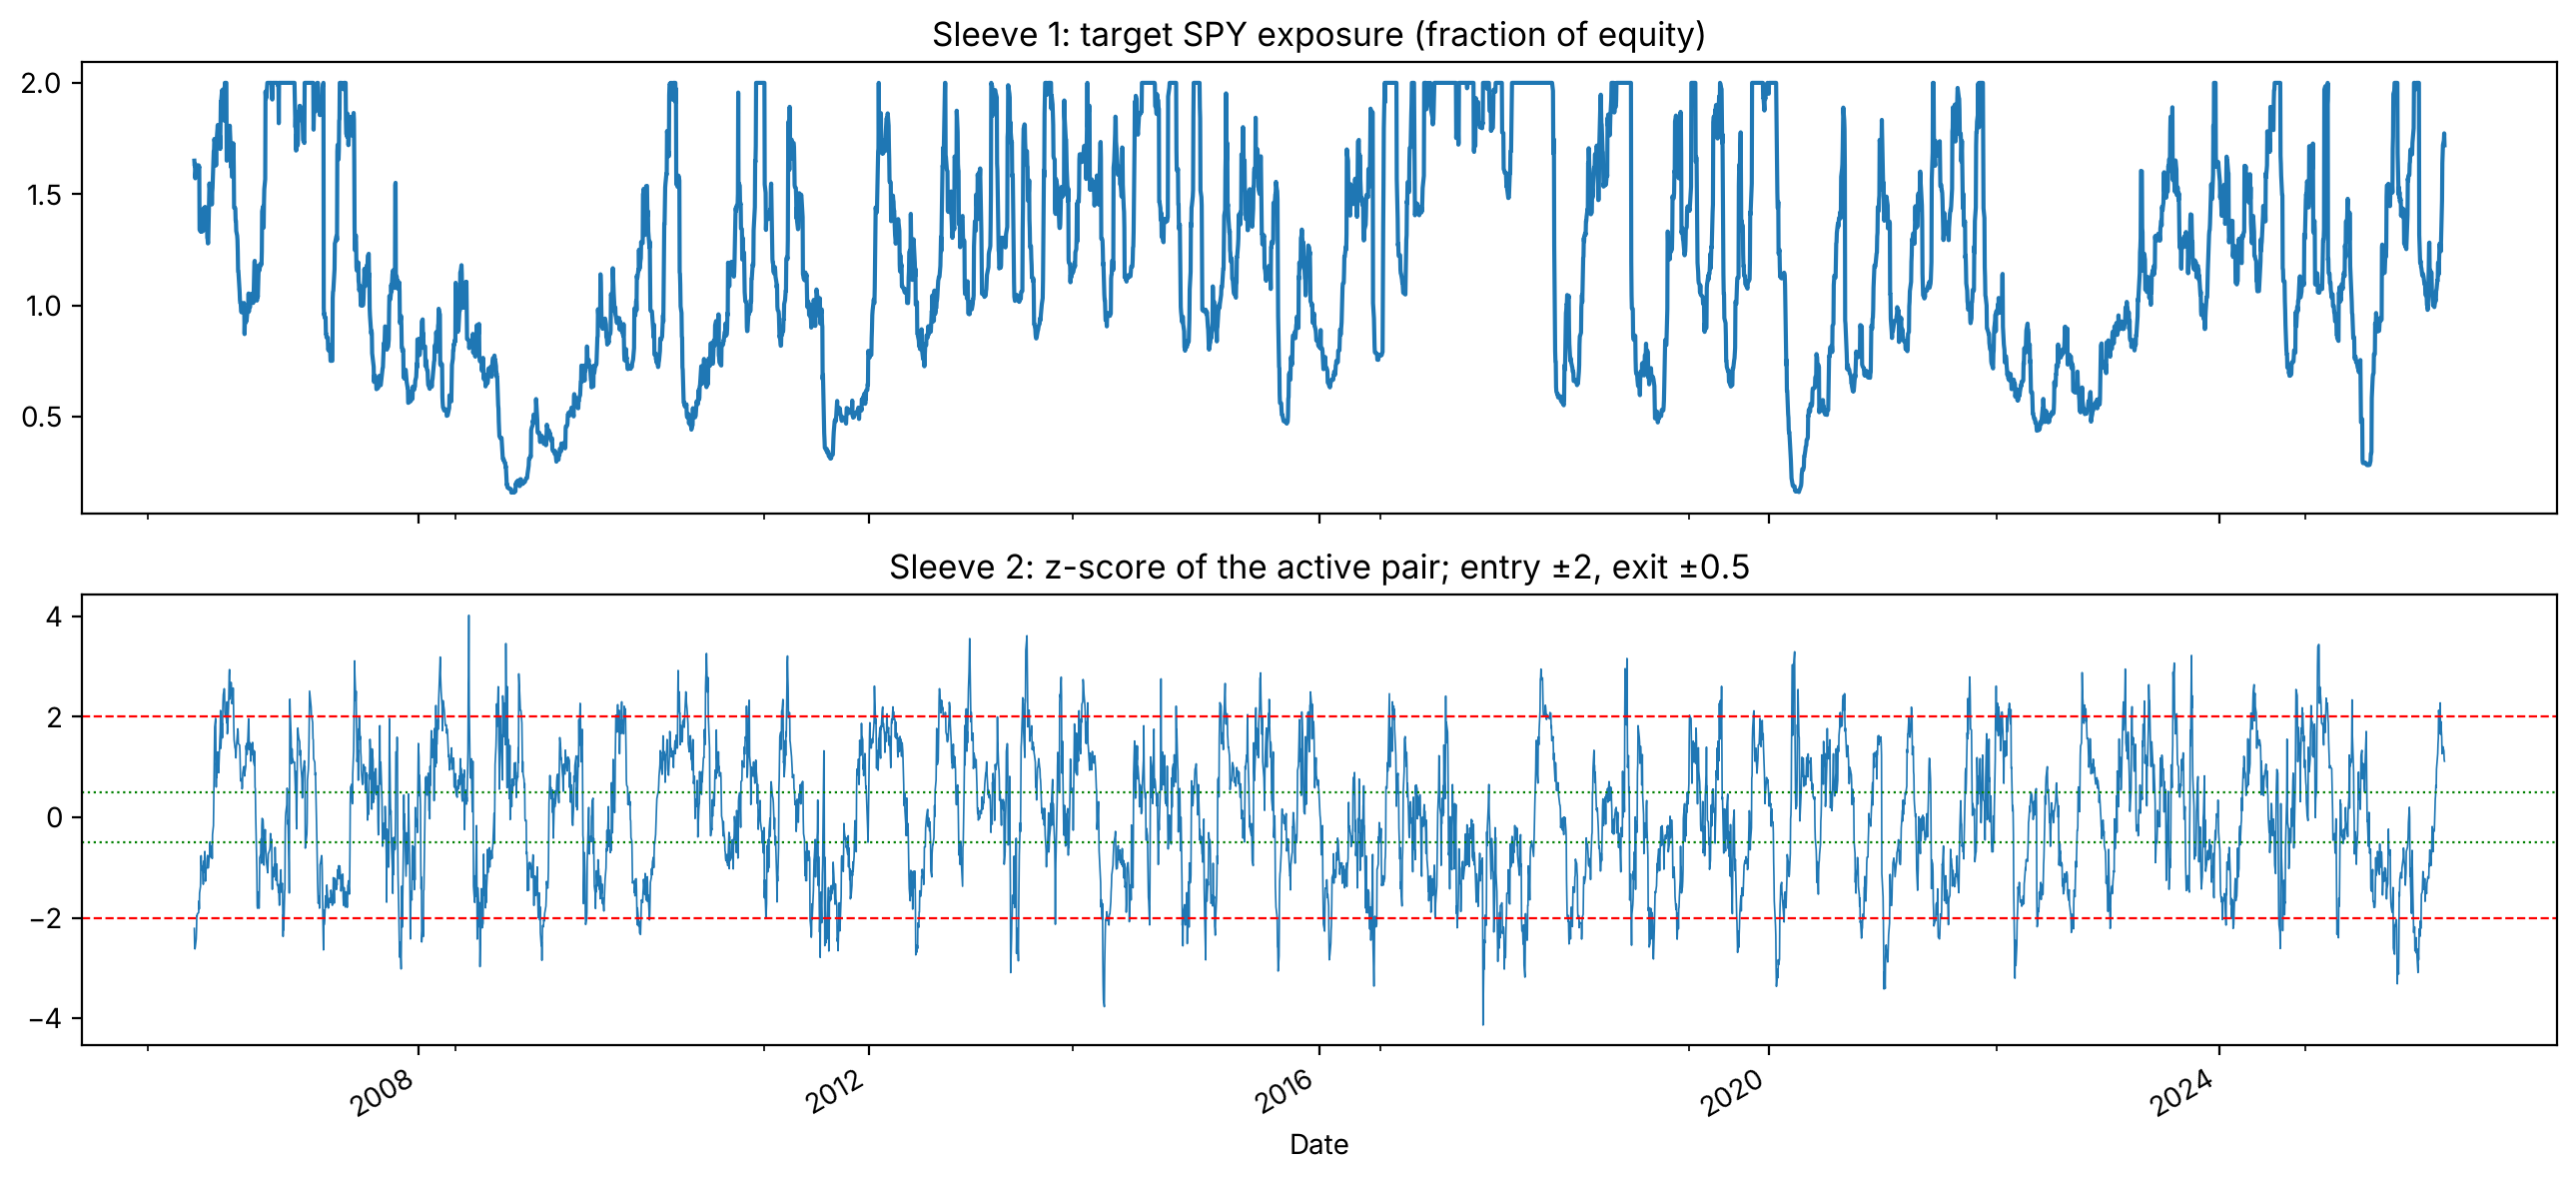

pair position open on 42% of days


In [7]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
expo.loc[START:END].plot(ax=ax[0], title='Sleeve 1: target SPY exposure (fraction of equity)')
z_active.loc[START:END].plot(ax=ax[1], lw=.6, title='Sleeve 2: z-score of the active pair; entry ±2, exit ±0.5')
for h in [Z_IN, -Z_IN]: ax[1].axhline(h, c='r', ls='--', lw=.8)
for h in [Z_OUT, -Z_OUT]: ax[1].axhline(h, c='g', ls=':', lw=.8)
plt.tight_layout(); plt.show()
open_ = tgt_pair.abs().sum(axis=1).loc[START:END] > 0
print(f'pair position open on {open_.mean():.0%} of days')

### backtest
- weights from close t−1 earn day t. cash earns rf, borrowed cash pays rf + 50bp, shorts pay 25bp p.a.
- positions drift with prices, no implicit daily rebalance
- trades only at month-end (spy) or when the pair target changes
- cost = `COST × |target − drifted|`
- `lag=2` → trade one day later

In [8]:
def backtest(px, use_spy=True, pair_size=PAIR_SIZE, cost=COST, lag=1, pair_kw={}):
    e = spy_exposure(px) if use_spy else 0 * px['SPY']
    P = pair_targets(px, **pair_kw)[0] * pair_size
    me = pd.Series(month_end_flag(px.index), index=px.index)
    e, P, me = e.shift(lag - 1), P.shift(lag - 1).fillna(0), me.shift(lag - 1, fill_value=False)   # lag=2: trade a day late

    idx = px.loc[:END].index[px.index.searchsorted(pd.Timestamp(START)) - 1:]   # from the last close before START
    R, rf = px[ASSETS].pct_change().loc[idx].values, rf_d.loc[idx].values
    e, P, me = e.loc[idx].values, P.loc[idx].values, me.loc[idx].values

    w, rows = np.zeros(len(ASSETS)), []                               # weights: spy + 9 sectors, rest is cash
    for i in range(len(idx)):
        cash = 1 - w.sum()
        gross = w @ R[i] + cash * (rf[i] + (FIN_SPREAD / 252 if cash < 0 else 0)) \
                - np.abs(np.minimum(w, 0)).sum() * SHORT_FEE / 252
        drift = w * (1 + R[i]) / (1 + gross)                          # positions drift with prices
        tgt = drift.copy()
        if i == 0 or me[i]: tgt[0] = e[i]                             # spy: reset at month-end
        if i == 0 or (P[i] != P[i - 1]).any(): tgt[1:] = P[i]         # pair: trade only when the target changes
        turn = np.abs(tgt - drift).sum()
        rows.append((gross, gross - turn * cost, turn, tgt[0], np.abs(tgt).sum()))
        w = tgt
    out = pd.DataFrame(rows, index=idx, columns=['gross', 'net', 'turnover', 'w_spy', 'gross_exposure'])
    return out.iloc[1:]                                               # returns start the day after START's close

bt = backtest(px)
print(bt.describe().T[['mean', 'min', 'max']])

                    mean       min       max
gross           0.000825 -0.086894  0.103901
net             0.000723 -0.086894  0.103901
turnover        0.101858  0.000000  2.595132
w_spy           1.202824  0.129528  2.165231
gross_exposure  2.061788  0.129528  4.426773


### look-ahead check
drop all data after a cutoff, assert signals, pairs and returns before it are unchanged.

In [9]:
for cut in ['2010-06-30', '2015-12-31', '2020-03-31']:
    px_cut = px.loc[:cut]
    assert np.allclose(spy_exposure(px).loc[:cut].dropna(), spy_exposure(px_cut).dropna())
    assert np.allclose(pair_targets(px)[0].loc[:cut], pair_targets(px_cut)[0])
    full, trunc = backtest(px).loc[:cut], backtest(px_cut)
    assert np.allclose(full.values, trunc.values), cut
    print(f'cut-off {cut}: signals, pair choices and {len(trunc)} daily returns identical with and without future data ✓')

cut-off 2010-06-30: signals, pair choices and 1131 daily returns identical with and without future data ✓


cut-off 2015-12-31: signals, pair choices and 2517 daily returns identical with and without future data ✓


cut-off 2020-03-31: signals, pair choices and 3585 daily returns identical with and without future data ✓


dividend adjustment scales all prices before a dividend by one factor → constant shift in `log(a/b)` within the window → cancels in the z-score. returns unaffected.

### performance

In [10]:
monthly = lambda r: (1 + r).resample('ME').prod() - 1
bench_d = ret['^SP500TR'].loc[bt.index]
rf_m = monthly(rf_d.loc[bt.index])
bench_m = monthly(bench_d)

def stats(r_m):
    # Monthly-return statistics. Means x12, volatilities x sqrt(12); beta not annualised.
    rf, b = rf_m.loc[r_m.index], bench_m.loc[r_m.index]
    ex, bex = r_m - rf, b - rf
    ols = sm.OLS(ex, sm.add_constant(bex)).fit()
    a, beta = ols.params.iloc[0], ols.params.iloc[1]
    wealth = (1 + r_m).cumprod()
    return pd.Series({
        'Ann. avg return': r_m.mean() * 12,
        'Ann. volatility': r_m.std() * np.sqrt(12),
        'Sharpe ratio': ex.mean() / ex.std() * np.sqrt(12),
        'Alpha (ann.)': a * 12,
        'Alpha t-stat': ols.tvalues.iloc[0],
        'Beta': beta,
        'Information ratio': a / ols.resid.std() * np.sqrt(12),
        'Max drawdown (monthly)': (wealth / wealth.cummax() - 1).min(),
    })

strat_m = monthly(bt.net)
table = pd.DataFrame({'Strategy (net)': stats(strat_m), 'Strategy (gross)': stats(monthly(bt.gross)),
                      'S&P 500 TR': stats(bench_m)})
table.loc[['Alpha t-stat', 'Information ratio'], 'S&P 500 TR'] = np.nan   # benchmark regressed on itself: undefined
print(f'{len(strat_m)} monthly observations, {strat_m.index[0]:%Y-%m} to {strat_m.index[-1]:%Y-%m}')
table.round(4)

240 monthly observations, 2006-01 to 2025-12


,Strategy (net),Strategy (gross),S&P 500 TR
Ann. avg return,0.1746,0.2005,0.1163
Ann. volatility,0.1566,0.1570,0.1509
Sharpe ratio,1.0115,1.1742,0.6630
Alpha (ann.),0.0739,0.1005,-0.0000
Alpha t-stat,3.5568,4.7345,NaN
Beta,0.8435,0.8378,1.0000
Information ratio,0.8115,1.0802,NaN
Max drawdown (monthly),-0.2678,-0.2346,-0.5095


- monthly returns compounded from daily, 2006-01 → 2025-12
- ann. return = mean × 12, vol = std × √12
- sharpe = mean(r − rf) / std(r − rf) × √12
- ols: `r − rf = α + β (r_bench − rf) + ε`. α × 12, β not annualised
- ir = α / σ(ε) × √12
- net = after 10bp per unit traded, financing, borrow fee. no taxes

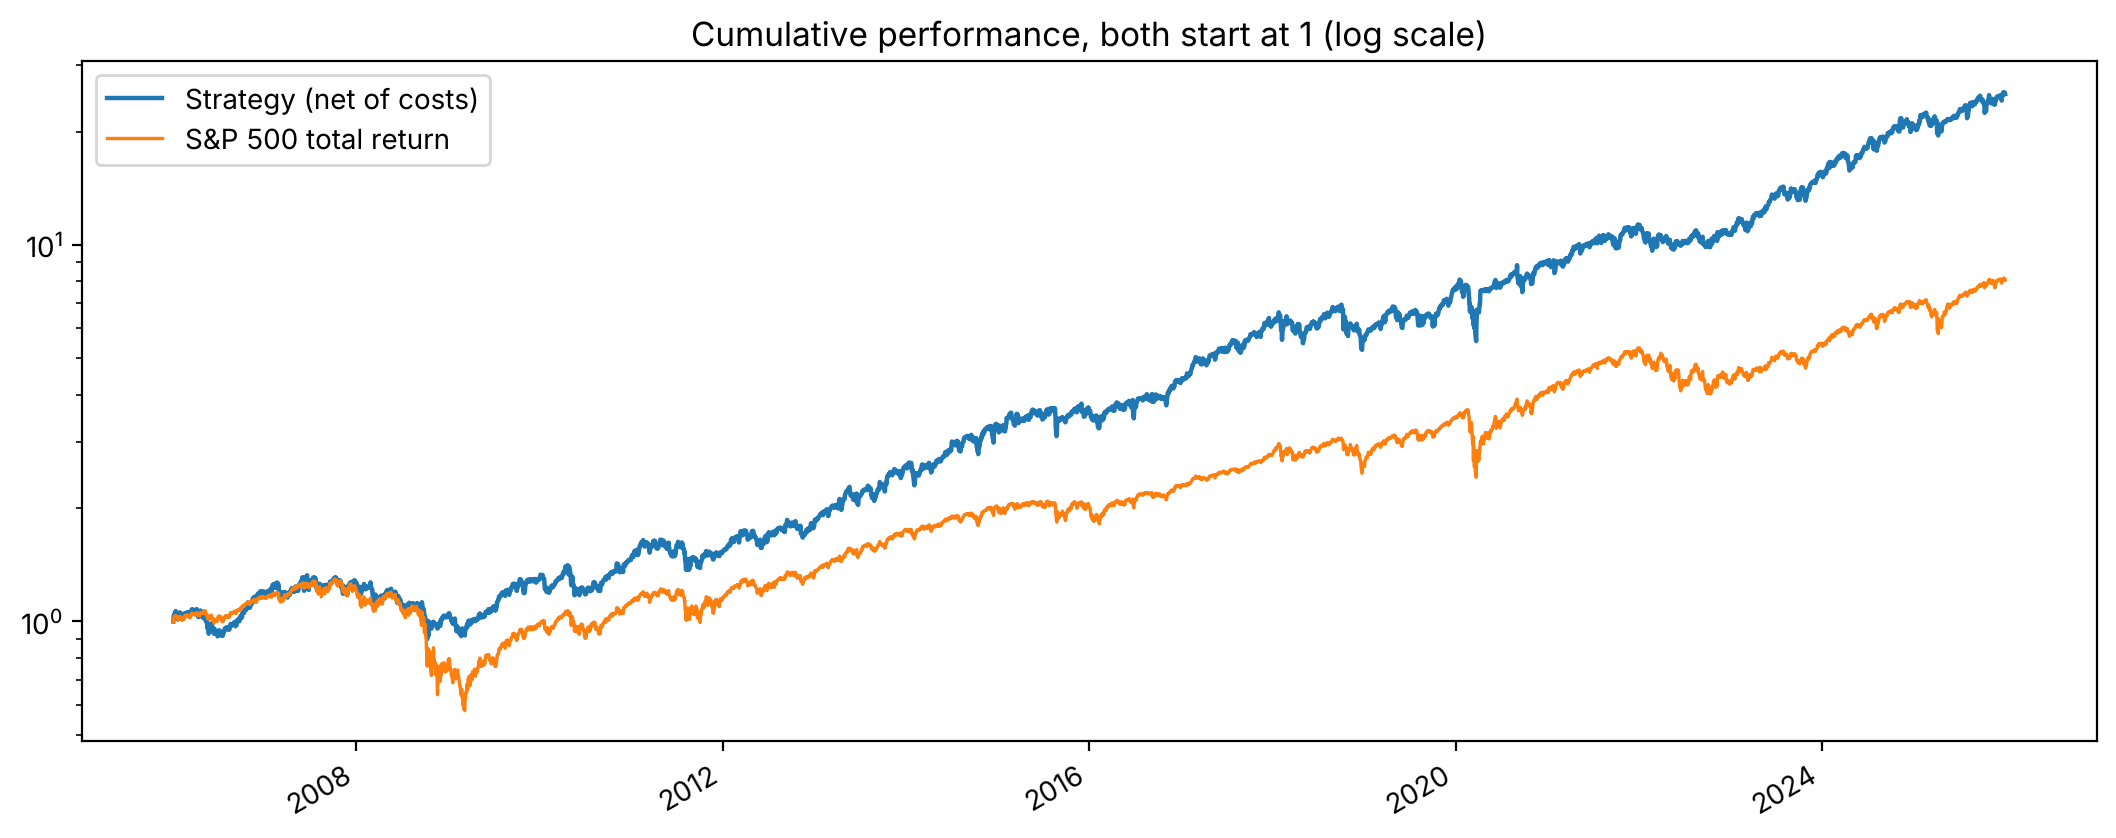

$1 grew to: strategy 25.16, S&P 500 TR 8.06


In [11]:
def wealth(r):
    w = (1 + r).cumprod()
    return pd.concat([pd.Series(1.0, index=[w.index[0] - pd.Timedelta(days=1)]), w])

fig, ax = plt.subplots(figsize=(13, 5))
wealth(bt.net).plot(ax=ax, label='Strategy (net of costs)', lw=1.6)
wealth(bench_d).plot(ax=ax, label='S&P 500 total return', lw=1.2)
ax.set_yscale('log'); ax.set_title('Cumulative performance, both start at 1 (log scale)'); ax.legend(); plt.show()
print(f'$1 grew to: strategy {wealth(bt.net).iloc[-1]:.2f}, S&P 500 TR {wealth(bench_d).iloc[-1]:.2f}')

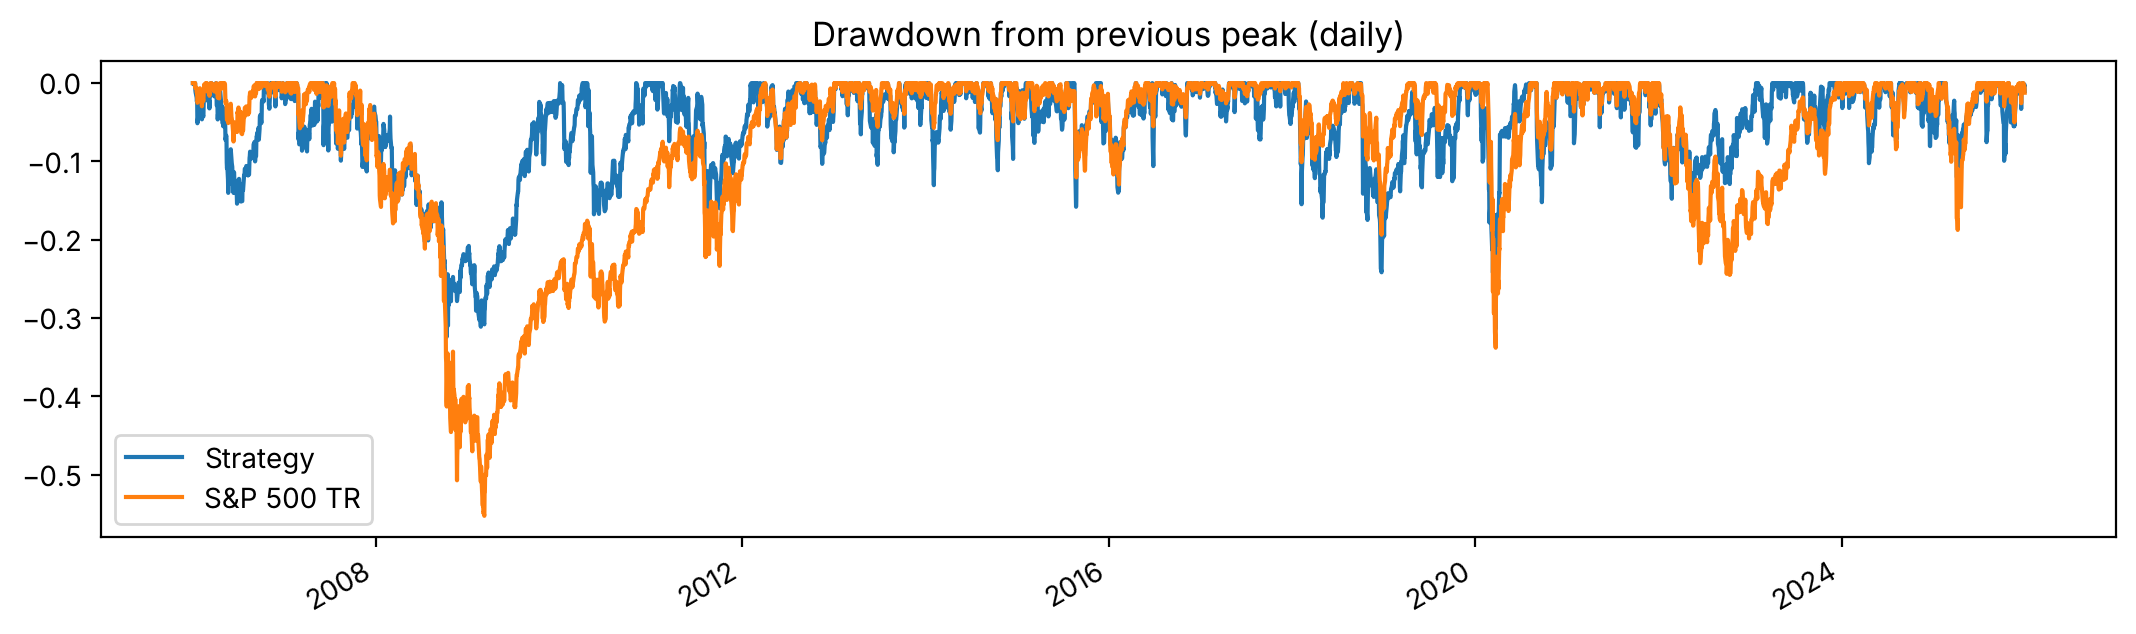

daily max drawdown: strategy -32.4%, benchmark -55.3%


In [12]:
dd = lambda r: wealth(r) / wealth(r).cummax() - 1
fig, ax = plt.subplots(figsize=(13, 3.5))
dd(bt.net).plot(ax=ax, label='Strategy'); dd(bench_d).plot(ax=ax, label='S&P 500 TR')
ax.set_title('Drawdown from previous peak (daily)'); ax.legend(); plt.show()
print('daily max drawdown: strategy {:.1%}, benchmark {:.1%}'.format(dd(bt.net).min(), dd(bench_d).min()))

### attribution

In [13]:
spy_only  = backtest(px, use_spy=True,  pair_size=0)      # sleeve 1 alone, pair switched off
pair_only = backtest(px, use_spy=False, pair_size=1.0)    # sleeve 2 alone, capital otherwise in T-bills
sleeves = {'Vol-managed SPY only': spy_only.net, 'Pair only (+ T-bills)': pair_only.net, 'Combined strategy': bt.net}
attr = pd.DataFrame({k: stats(monthly(v)) for k, v in sleeves.items()})
attr.loc['Ann. excess return over T-bills'] = {k: (monthly(v) - rf_m).mean() * 12 for k, v in sleeves.items()}
attr.loc['$1 grows to'] = {k: wealth(v).iloc[-1] for k, v in sleeves.items()}
print('correlation of monthly returns, SPY sleeve vs pair sleeve:',
      round(monthly(spy_only.net).corr(monthly(pair_only.net)), 3))
attr.round(4)

correlation of monthly returns, SPY sleeve vs pair sleeve: -0.09


,Vol-managed SPY only,Pair only (+ T-bills),Combined strategy
Ann. avg return,0.1293,0.0626,0.1746
Ann. volatility,0.1455,0.0725,0.1566
Sharpe ratio,0.7773,0.6419,1.0115
Alpha (ann.),0.0290,0.0463,0.0739
Alpha t-stat,1.7831,2.8066,3.5568
Beta,0.8409,0.0011,0.8435
Information ratio,0.4068,0.6404,0.8115
Max drawdown (monthly),-0.3278,-0.1459,-0.2678
Ann. excess return over T-bills,0.1131,0.0464,0.1583
$1 grows to,10.6108,3.3098,25.1584


Excess return: SPY sleeve 11.31% + pair 4.64% = 15.95% (combined actual 15.83%; the gap is compounding/interaction)
Share of excess return: SPY sleeve 71%, pair 29%
Alpha: SPY sleeve 2.90%, pair 4.63%, combined 7.39%


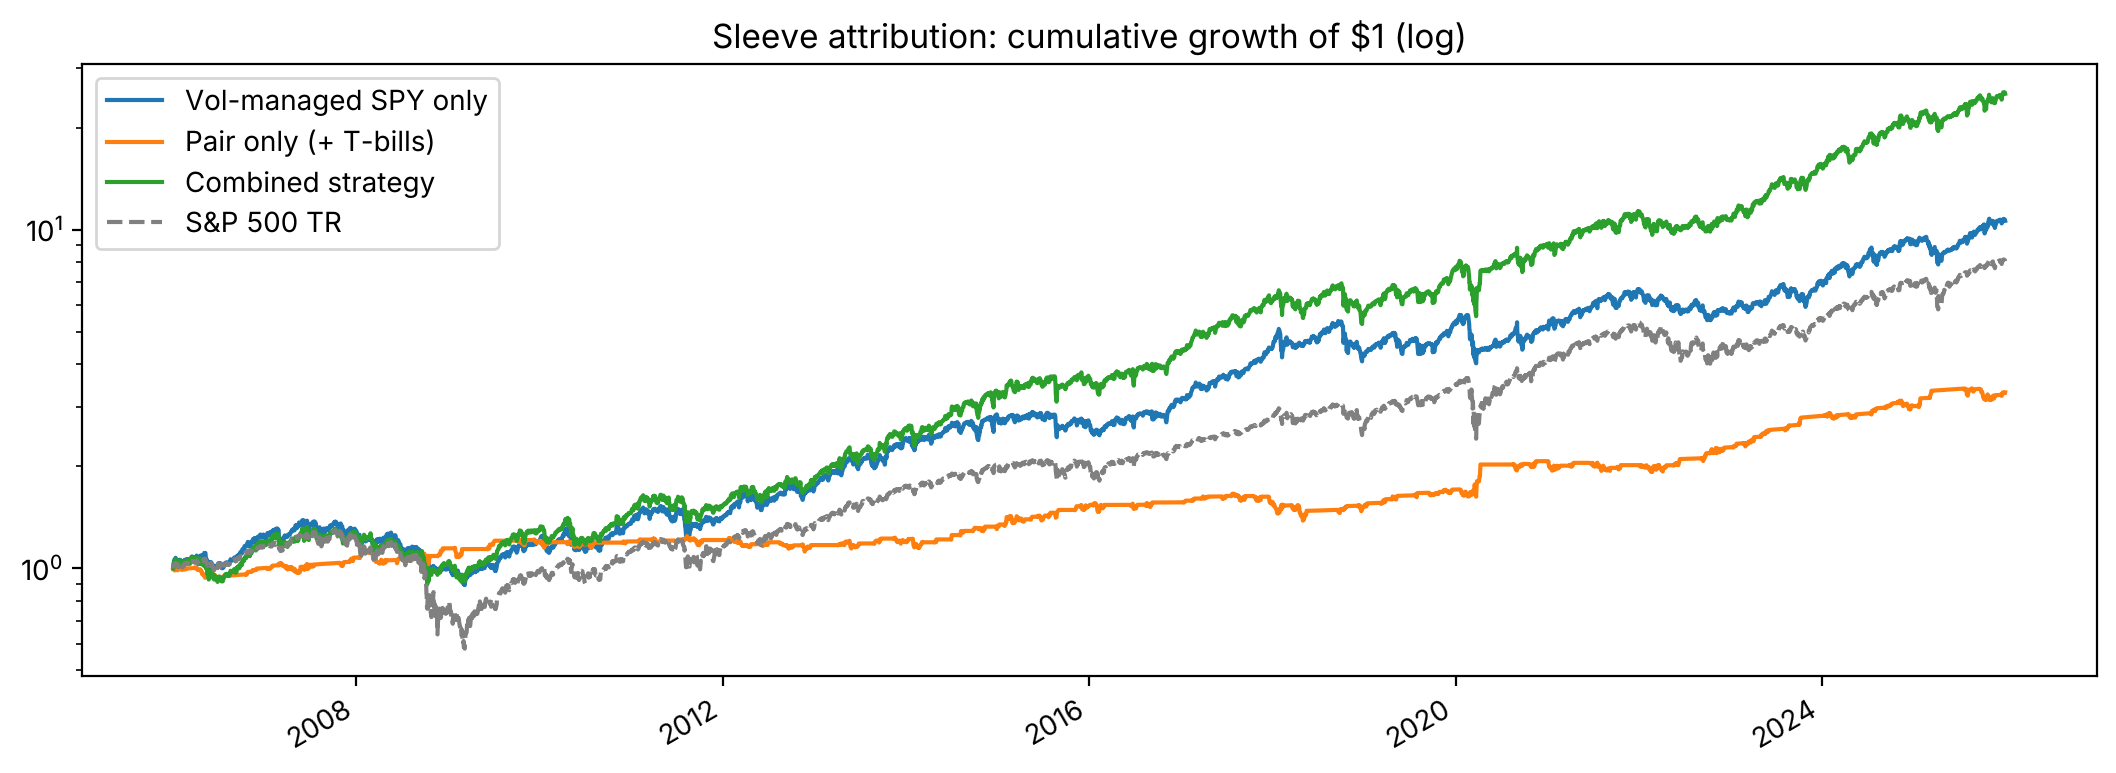

In [14]:
ex = attr.loc['Ann. excess return over T-bills']
share = ex.iloc[:2] / ex.iloc[:2].sum()
print(f"Excess return: SPY sleeve {ex.iloc[0]:.2%} + pair {ex.iloc[1]:.2%} = {ex.iloc[:2].sum():.2%} "
      f"(combined actual {ex.iloc[2]:.2%}; the gap is compounding/interaction)")
print(f"Share of excess return: SPY sleeve {share.iloc[0]:.0%}, pair {share.iloc[1]:.0%}")
al = attr.loc['Alpha (ann.)']
print(f"Alpha: SPY sleeve {al.iloc[0]:.2%}, pair {al.iloc[1]:.2%}, combined {al.iloc[2]:.2%}")
fig, ax = plt.subplots(figsize=(13, 4.5))
for k, v in sleeves.items(): wealth(v).plot(ax=ax, label=k)
wealth(bench_d).plot(ax=ax, label='S&P 500 TR', ls='--', c='grey')
ax.set_yscale('log'); ax.set_title('Sleeve attribution: cumulative growth of $1 (log)'); ax.legend(); plt.show()

### implementation

In [15]:
years = len(bt) / 252
gross_pair = tgt_pair.abs().sum(axis=1)
impl = pd.Series({
    'Turnover per year (x equity)': bt.turnover.sum() / years,
    'Annual cost drag (gross - net)': (bt.gross - bt.net).sum() / years,
    'Avg SPY exposure': bt.w_spy.mean(),
    'Avg gross exposure': bt.gross_exposure.mean(),
    'Max gross exposure': bt.gross_exposure.max(),
    'Pair trades opened': int(((gross_pair > 0) & (gross_pair.shift() == 0)).loc[START:END].sum()),
})
print(impl.round(3).to_string())

be = {c: stats(monthly(backtest(px, cost=c / 1e4).net))['Sharpe ratio'] for c in [0, 5, 10, 20, 30, 50]}
print('\nSharpe ratio by cost per unit traded (bp):', {k: round(float(v), 2) for k, v in be.items()})

Turnover per year (x equity)       25.668
Annual cost drag (gross - net)      0.026
Avg SPY exposure                    1.203
Avg gross exposure                  2.062
Max gross exposure                  4.427
Pair trades opened                107.000



Sharpe ratio by cost per unit traded (bp): {0: 1.17, 5: 1.09, 10: 1.01, 20: 0.85, 30: 0.68, 50: 0.35}


### robustness

In [16]:
rob = pd.DataFrame({
    'Base case':                 stats(strat_m),
    'Execution lag 2 days':      stats(monthly(backtest(px, lag=2).net)),
    f'In-sample ..{IS_END[:4]}': stats(strat_m.loc[:IS_END]),
    f'Out-of-sample {int(IS_END[:4]) + 1}..': stats(strat_m.loc[IS_END:].iloc[1:]),
}).loc[['Ann. avg return', 'Ann. volatility', 'Sharpe ratio', 'Alpha (ann.)', 'Beta', 'Information ratio']]
rob.round(4)

,Base case,Execution lag 2 days,In-sample ..2015,Out-of-sample 2016..
Ann. avg return,0.1746,0.1677,0.1405,0.2086
Ann. volatility,0.1566,0.1561,0.1477,0.1650
Sharpe ratio,1.0115,0.9709,0.8755,1.1350
Alpha (ann.),0.0739,0.0694,0.0733,0.0716
Beta,0.8435,0.8200,0.7898,0.8961
Information ratio,0.8115,0.7308,0.8346,0.7624


In [17]:
grid = pd.DataFrame({w: {zi: stats(monthly(backtest(px, use_spy=False, pair_kw=dict(win=w, z_in=zi)).net))['Sharpe ratio']
                         for zi in [1.5, 2.0, 2.5]} for w in [40, 60, 90, 120]}).T
grid.index.name, grid.columns.name = 'window (days)', 'entry z'
print('Pair sleeve alone, net Sharpe ratio across signal parameters (base case: 60 days, z = 2.0):')
grid.round(2)

Pair sleeve alone, net Sharpe ratio across signal parameters (base case: 60 days, z = 2.0):


entry z,1.5,2.0,2.5
window (days),,,
40,0.01,0.45,0.18
60,0.36,0.64,0.62
90,0.59,0.64,0.82
120,0.63,0.70,0.75


#### pair selection bias
xlu/xlp looked good in exploration, the low-beta rule came after. tested against 3y/5y betas, a one-off 1999–2005 pick, fixed xlu/xlp, and all 36 fixed pairs.

In [18]:
def pair_sharpes(**kw):
    p = backtest(px, use_spy=False, pair_kw=kw).net
    c = backtest(px, pair_kw=kw).net
    return pd.Series({'Pair sleeve Sharpe': stats(monthly(p))['Sharpe ratio'],
                      'Combined Sharpe': stats(monthly(c))['Sharpe ratio']})

static_pair = tuple(sorted(sector_betas(px, '1999', '2005').nsmallest(2).index))
rules = {
    'Base: lowest-beta pair, 1y betas':   {},
    'Lowest-beta pair, 3y betas':         dict(pick=lambda px, y: lowbeta_pick(px, y, 3)),
    'Lowest-beta pair, 5y betas':         dict(pick=lambda px, y: lowbeta_pick(px, y, 5)),
    f'Static: 1999-2005 betas ({"/".join(static_pair)})': dict(pick=lambda px, y: static_pair),
    'Fixed XLP/XLU (hindsight)':          dict(pick=lambda px, y: ('XLP', 'XLU')),
}
pd.DataFrame({k: pair_sharpes(**v) for k, v in rules.items()}).T.round(2)

,Pair sleeve Sharpe,Combined Sharpe
"Base: lowest-beta pair, 1y betas",0.64,1.01
"Lowest-beta pair, 3y betas",0.58,0.97
"Lowest-beta pair, 5y betas",0.49,0.92
Static: 1999-2005 betas (XLE/XLP),-0.11,0.40
Fixed XLP/XLU (hindsight),0.69,1.04


In [19]:
from itertools import combinations
all36 = pd.Series({f'{a}/{b}': stats(monthly(backtest(px, use_spy=False, pair_kw=dict(pick=lambda px, y, a=a, b=b: (a, b))).net))['Sharpe ratio']
                   for a, b in combinations(SECTORS, 2)}).sort_values(ascending=False)
print(f'All 36 fixed sector pairs, pair sleeve net Sharpe: mean {all36.mean():.2f}, median {all36.median():.2f}, '
      f'{(all36 > 0).sum()} of 36 positive; XLP/XLU ranks #{all36.index.get_loc("XLP/XLU") + 1}')
all36.round(2).to_frame('Sharpe').T

All 36 fixed sector pairs, pair sleeve net Sharpe: mean -0.01, median -0.04, 17 of 36 positive; XLP/XLU ranks #1


,XLP/XLU,XLU/XLV,XLB/XLI,XLB/XLP,XLK/XLU,XLB/XLY,XLB/XLK,XLF/XLI,XLB/XLV,XLF/XLK,...,XLE/XLK,XLI/XLP,XLU/XLY,XLE/XLF,XLF/XLP,XLP/XLY,XLE/XLU,XLI/XLY,XLE/XLY,XLI/XLV
Sharpe,0.69,0.34,0.34,0.28,0.23,0.18,0.16,0.13,0.11,0.09,...,-0.15,-0.17,-0.17,-0.18,-0.21,-0.22,-0.22,-0.35,-0.38,-0.41


In [20]:
yearly = pd.DataFrame({'Strategy': (1 + bt.net).groupby(bt.index.year).prod() - 1,
                       'SPY sleeve': (1 + spy_only.net).groupby(spy_only.index.year).prod() - 1,
                       'Pair sleeve': (1 + pair_only.net).groupby(pair_only.index.year).prod() - 1,
                       'S&P 500 TR': (1 + bench_d).groupby(bench_d.index.year).prod() - 1})
print('years strategy beat benchmark:', (yearly.Strategy > yearly['S&P 500 TR']).sum(), 'of', len(yearly))
out = (yearly * 100).round(1)
out['pair held'] = betas['pair held'].reindex(out.index)
out

years strategy beat benchmark: 16 of 20


,Strategy,SPY sleeve,Pair sleeve,S&P 500 TR,pair held
Date,,,,,
2006,19.0,24.6,0.3,15.8,XLP/XLV
2007,6.8,3.8,7.4,5.5,XLP/XLU
2008,-18.6,-22.5,6.5,-37.0,XLP/XLV
2009,24.9,19.1,5.2,26.5,XLP/XLV
2010,12.7,13.5,-0.4,15.1,XLP/XLV
2011,4.5,3.7,1.0,2.1,XLP/XLU
2012,18.1,22.1,-3.4,16.0,XLP/XLU
2013,44.6,41.6,2.3,32.4,XLP/XLU
2014,26.1,13.7,11.4,13.7,XLP/XLU


### risks
- selection bias: rule came after seeing xlu/xlp. holds for 1/3/5y betas, fails for a one-off 1999–2005 pick and for the average fixed pair → read pair alpha as optimistic. params are defaults, not tuned
- survivorship: none, all etfs live since 1998
- leverage: gross can exceed 4x (2x spy + 2 × 1x legs), needs margin. financing at fixed spreads
- concentration: one equity index, two defensive sectors
- regime: monthly vol reset lags fast crashes. pair can decouple
- data: `^IRX` is a discount yield, approximates t-bill return. yahoo not point-in-time

### ai disclosure
claude code used for strategy screening (`sandbox/`) and writing/debugging this notebook. checked via look-ahead test, spy vs `^SP500TR`, gross vs net + cost breakeven, selection-bias checks, fresh colab rerun. instructor approval: _todo_